# 5. M6: fine-tuned InLegalBERT, learning from the keywords and the lawyers

Steps 1 and 2 encode the lawyers' knowledge as rules: their keyword lists (M0), revised with their highlights (M1). Here a model learns from both and then labels sentences on its own. This notebook fine-tunes InLegalBERT itself, so the encoder also adapts to the categories.

**Stage 1, keyword labels.** InLegalBERT is fine-tuned to predict M1's labels for every sentence of the judgments the lawyers did *not* annotate. This gives thousands of training sentences at no annotation cost, but the labels are noisy: they are whatever the keyword rules say.

**Stage 2, lawyer labels.** The stage 1 model is fine-tuned further on the lawyers' highlighted sentences from the dev judgments. This teaches it where the lawyers disagree with the rules.

**Context.** With `CONTEXT = 1` the model reads each sentence together with the sentence before and after it in the same judgment (`[CLS] sentence [SEP] previous [SEP] next [SEP]`, the sentence in segment 0 so the model knows which one it labels). A sentence such as "These complaints were more or less Naraji petitions" is procedural reasoning only in light of its neighbours; most errors in legal argument classification come from missing context (Habernal et al., 2023). The reported model uses the sentence only (`CONTEXT = 0`). The context run is an ablation, saved under `argument_mining/ablation_context/`, and is not part of the main comparison.

**Variants** (an ablation of the two stages):

| Name | Stage 1 (keyword labels) | Stage 2 (lawyer labels) |
|---|---|---|
| M6s | yes | no |
| M6g | no, starts from plain InLegalBERT | yes |
| M6 | yes | yes |

**Keeping the evaluation honest**
* Stage 1 never sees a sentence from any annotated judgment, dev or test.
* Dev scores for M6g and M6 come from cross validation over dev judgments: each dev judgment is scored by a model that did not train on it.
* The final M6g and M6 models train on all dev judgments, then score the test judgments once.
* M6s, M6g and M6 use settings fixed in advance. A later section searches stage 2 settings on dev judgments only (cross validation) and saves the best as M6t; every setting tried is saved for reporting.

**Reads:** sentences, gold sentences, M1 predictions from `03_keyword_methods`. **Writes:** predictions for M6s, M6g, M6 and M6t in `predictions/`, `stage2_grid.csv` and `stage2_grid.png` (`stage2_grid_context1.*` with context), and the stage 1 model in `intermediate/models/`, so a re-run skips stage 1.

The first run takes about 1.5 to 2 hours on an Apple silicon Mac (stage 1 about 15 minutes, the settings search about an hour). Stage 1 and finished search settings are cached, so later runs are much faster.

## Setup

In [1]:
import os
os.environ.setdefault("PYTORCH_ENABLE_MPS_FALLBACK", "1")   # run any operation MPS lacks on the CPU

from argmine_common import *
import json
import time
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup
from transformers.utils import logging as hf_logging
hf_logging.set_verbosity_error()

SILVER_METHOD = "M1 revised keywords"   # stage 1 labels: the best keyword method on dev
CONTEXT = 0                             # neighbouring sentences on each side fed with the sentence; 0 = sentence only
SENT_LEN = 128                          # tokens kept from the sentence being labelled
MAX_LEN = SENT_LEN if CONTEXT == 0 else 256   # tokens per input, sentence plus context
TAG = "" if CONTEXT == 0 else f" + context ±{CONTEXT}"   # added to method names, so both versions can be compared
BATCH = 16
STAGE1 = dict(epochs=2, lr=3e-5)        # keyword labels, about 9,000 sentences
STAGE2 = dict(epochs=8, lr=3e-5)        # lawyer labels, about 300 sentences per fold
N_FOLDS = 4                             # cross validation folds over dev judgments
THRESHOLD = 0.5
MAX_POS_WEIGHT = 20                     # cap on the up weighting of rare positive labels

sents = load_sentences()
GOLD_IDX, Y, DOCS, gold_docs, TEST = load_gold()
preds = load_preds()
if SILVER_METHOD not in preds:
    raise FileNotFoundError(f"No predictions for {SILVER_METHOD}. Run 03_keyword_methods.ipynb first.")
SILVER = preds[SILVER_METHOD]["all"]

DEVICE = torch.device("cuda" if torch.cuda.is_available()
                      else "mps" if torch.backends.mps.is_available() else "cpu")
MODEL_DIR = DATA_DIR / "models"
print("Device:", DEVICE)

Skipping M4 hybrid M1 + M2: saved before the gold set changed. Re-run its notebook.
Skipping M6 fine-tuned, keywords then highlights: saved before the gold set changed. Re-run its notebook.
Skipping M6g fine-tuned on lawyer highlights: saved before the gold set changed. Re-run its notebook.
Skipping M6s fine-tuned on keyword labels: saved before the gold set changed. Re-run its notebook.
Skipping M6t fine-tuned, stage 2 tuned on dev: saved before the gold set changed. Re-run its notebook.
Device: mps


## Training data and folds

In [2]:
silver_idx = np.where(~sents.doc_id.isin(set(gold_docs)).values)[0]
dev_docs = sorted(set(DOCS[~TEST]))
FOLDS = [list(f) for f in np.array_split(np.random.default_rng(SEED).permutation(dev_docs), N_FOLDS)]
ROWS = {d: np.where(DOCS == d)[0] for d in gold_docs}
ALL_IDX = np.arange(len(sents))
TEST_ROWS = np.where(TEST)[0]

def rows_of(docs):
    return np.concatenate([ROWS[d] for d in docs])

print(f"Stage 1: {len(silver_idx):,} sentences from {sents.doc_id.iloc[silver_idx].nunique()} unannotated judgments")
print(pd.Series(SILVER[silver_idx].sum(0), index=[SHORT[c] for c in CATS], name="keyword positives").to_string())
print(f"\nStage 2: {(~TEST).sum()} lawyer labelled sentences from {len(dev_docs)} dev judgments, "
      f"{N_FOLDS} folds of {[len(f) for f in FOLDS]} judgments")
print(f"Test: {TEST.sum()} sentences from {len(set(DOCS[TEST]))} judgments, never trained on")

Stage 1: 9,159 sentences from 281 unannotated judgments
Ingredients/exceptions    674
Speech vs reputation      190
Procedural                344
Insufficient evidence     130
Abuse of process          161

Stage 2: 460 lawyer labelled sentences from 13 dev judgments, 4 folds of [4, 3, 3, 3] judgments
Test: 67 sentences from 3 judgments, never trained on


## Fine-tuning helpers

In [3]:
tok = AutoTokenizer.from_pretrained(ENCODER_NAME)

def with_context(k):
    # [CLS] sentence [SEP] previous sentences [SEP] following sentences [SEP]; segment 0 marks the sentence
    # being labelled. Context comes from the same judgment and is trimmed from the far ends first.
    sent = TOKS[k][:SENT_LEN - 2]
    same = DOC_OF == DOC_OF[k]
    prev = [t for j in range(max(k - CONTEXT, 0), k) if same[j] for t in TOKS[j]]
    nxt = [t for j in range(k + 1, min(k + 1 + CONTEXT, len(TOKS))) if same[j] for t in TOKS[j]]
    budget = MAX_LEN - len(sent) - 4
    n_prev = min(len(prev), max(budget // 2, budget - len(nxt)))
    prev, nxt = prev[len(prev) - n_prev:], nxt[:budget - n_prev]
    ctx = prev + [tok.sep_token_id] + nxt
    return {"input_ids": [tok.cls_token_id] + sent + [tok.sep_token_id] + ctx + [tok.sep_token_id],
            "token_type_ids": [0] * (len(sent) + 2) + [1] * (len(ctx) + 1)}

if CONTEXT == 0:
    enc = tok(sents.text.tolist(), truncation=True, max_length=MAX_LEN)
    ENC = [{"input_ids": i, "token_type_ids": t} for i, t in zip(enc["input_ids"], enc["token_type_ids"])]
else:
    TOKS = tok(sents.text.tolist(), add_special_tokens=False)["input_ids"]
    DOC_OF = sents.doc_id.values
    ENC = [with_context(k) for k in range(len(sents))]
print(f"Inputs: sentence{TAG or ' only'}, up to {MAX_LEN} tokens, "
      f"median {int(np.median([len(e['input_ids']) for e in ENC]))}")

def batches(ids, labels=None, shuffle=False, seed=SEED):
    # ids are row positions in `sents`; labels, if given, are aligned with ids
    order = np.random.default_rng(seed).permutation(len(ids)) if shuffle else np.arange(len(ids))
    for i in range(0, len(ids), BATCH):
        b = order[i:i + BATCH]
        x = tok.pad([ENC[ids[j]] for j in b], return_tensors="pt")
        x = {k: v.to(DEVICE) for k, v in x.items()}
        yield x, (None if labels is None else torch.tensor(labels[b], dtype=torch.float32, device=DEVICE))

def load_model(path=None):
    # path=None starts from plain InLegalBERT with a new classification head
    torch.manual_seed(SEED)
    return AutoModelForSequenceClassification.from_pretrained(path or ENCODER_NAME, num_labels=K).to(DEVICE)

def train(model, ids, labels, epochs, lr):
    pos = labels.sum(0)
    pos_weight = np.clip((len(labels) - pos) / np.maximum(pos, 1), 1, MAX_POS_WEIGHT)
    loss_fn = torch.nn.BCEWithLogitsLoss(pos_weight=torch.tensor(pos_weight, dtype=torch.float32, device=DEVICE))
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.01)
    steps = epochs * int(np.ceil(len(ids) / BATCH))
    sched = get_linear_schedule_with_warmup(opt, int(0.1 * steps), steps)
    model.train()
    for ep in range(epochs):
        t, total = time.time(), 0.0
        for x, yb in batches(ids, labels, shuffle=True, seed=SEED + ep):
            loss = loss_fn(model(**x).logits, yb)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step(); sched.step(); opt.zero_grad()
            total += loss.item() * len(yb)
        print(f"    epoch {ep + 1}/{epochs}: loss {total / len(ids):.4f} ({time.time() - t:.0f}s)")
    return model

@torch.no_grad()
def predict(model, ids):
    model.eval()
    probs = np.vstack([torch.sigmoid(model(**x).logits).float().cpu().numpy() for x, _ in batches(ids)])
    return (probs >= THRESHOLD).astype(int)

def free(model):
    del model
    if DEVICE.type == "mps":
        torch.mps.empty_cache()

Inputs: sentence only, up to 128 tokens, median 34


## Stage 1: learn from the keyword labels (M6s)

Cached in `intermediate/models/`, keyed on the training sentences, their labels and the settings, so it retrains only when one of those changes.

In [4]:
key = hashlib.md5((json.dumps([ENCODER_NAME, SILVER_METHOD, MAX_LEN, BATCH, STAGE1, SEED] + ([CONTEXT, SENT_LEN] if CONTEXT else []))
                   + "||".join(sents.text.iloc[silver_idx]) + SILVER[silver_idx].tobytes().hex()).encode()).hexdigest()[:10]
STAGE1_DIR = MODEL_DIR / f"stage1_{key}"

if STAGE1_DIR.exists():
    print(f"Loading cached stage 1 model from {STAGE1_DIR.relative_to(BASE)}")
    stage1 = load_model(STAGE1_DIR)
else:
    print("Training stage 1")
    stage1 = train(load_model(), silver_idx, SILVER[silver_idx], **STAGE1)
    stage1.save_pretrained(STAGE1_DIR)

# Stage 1 never saw an annotated judgment, so one model scores both dev and test
save_preds("M6s fine-tuned on keyword labels" + TAG, predict(stage1, GOLD_IDX), predict(stage1, np.arange(len(sents))))
free(stage1)

Training stage 1


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 37491.20it/s]

    epoch 1/2: loss 0.6065 (291s)


    epoch 2/2: loss 0.2389 (285s)


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  2.64it/s]

Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  2.61it/s]

## Stage 2: learn from the lawyers' highlights (M6g and M6)

For each variant: cross validation over dev judgments gives the dev predictions, then a final model trained on all dev judgments scores the test judgments and the whole corpus.

In [5]:
for name, init in [("M6g fine-tuned on lawyer highlights" + TAG, None),
                   ("M6 fine-tuned, keywords then highlights" + TAG, STAGE1_DIR)]:
    print(name)
    P = np.zeros((len(Y), K), dtype=int)
    for k, fold in enumerate(FOLDS):
        train_rows = rows_of([d for d in dev_docs if d not in fold])
        print(f"  fold {k + 1}/{N_FOLDS}: {len(train_rows)} training sentences")
        m = train(load_model(init), GOLD_IDX[train_rows], Y[train_rows], **STAGE2)
        r = rows_of(fold)
        P[r] = predict(m, GOLD_IDX[r])
        free(m)
    print("  final model, all dev judgments")
    dev_rows = np.where(~TEST)[0]
    m = train(load_model(init), GOLD_IDX[dev_rows], Y[dev_rows], **STAGE2)
    P[TEST_ROWS] = predict(m, GOLD_IDX[TEST_ROWS])
    save_preds(name, P, predict(m, ALL_IDX))
    free(m)

M6g fine-tuned on lawyer highlights
  fold 1/4: 270 training sentences


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 40769.13it/s]

    epoch 1/8: loss 1.1869 (9s)


    epoch 2/8: loss 1.1632 (9s)


...

    epoch 4/8: loss 0.4409 (15s)


    epoch 5/8: loss 0.2898 (15s)


    epoch 6/8: loss 0.1893 (15s)


    epoch 7/8: loss 0.1531 (15s)


    epoch 8/8: loss 0.1230 (15s)


## Stage 2 settings search (dev judgments only)

M6 above uses settings fixed in advance (learning rate 3e-5, 8 epochs, lawyer sentences only), and stage 2 made it worse than stage 1 alone. Two likely causes: too much training on about 300 sentences, and the model forgetting what stage 1 taught it. The search varies:

* **Learning rate** (`lr`).
* **Epochs**, 1 to `max_epochs`. The learning rate is constant after a short warmup, so the predictions after epoch *k* are those of a *k* epoch run, and one run scores every epoch count.
* **Keyword sentence mix** (`silver_mix`): stage 2 also trains on this many keyword labelled sentences per lawyer sentence, drawn from the unannotated judgments. This rehearsal keeps stage 1's knowledge from being overwritten. 0 means lawyer sentences only.

Every setting is scored with the same 4 fold cross validation over dev judgments. Test judgments are not used. Each setting's predictions are saved in `intermediate/stage2_grid/<stage 1 model>/`, and all scores in `argument_mining/stage2_grid.csv` and `stage2_grid.png`. The search resumes where it stopped if interrupted.

**For the paper:** report the whole grid. The best setting's dev score is optimistic, because it was chosen as the maximum of many dev scores; its test score is not.

In [6]:
from transformers import get_constant_schedule_with_warmup

GRID = dict(lr=[1e-5, 3e-5], silver_mix=[0, 1, 3], max_epochs=6)
GRID_DIR = DATA_DIR / "stage2_grid" / STAGE1_DIR.name   # a new stage 1 model starts a new search
GRID_DIR.mkdir(parents=True, exist_ok=True)
GRID_SLUG = "" if CONTEXT == 0 else f"_context{CONTEXT}"

def stage2_data(docs, silver_mix, seed):
    # Lawyer sentences of `docs`, plus silver_mix keyword labelled sentences per lawyer sentence
    r = rows_of(docs)
    ids, labels = GOLD_IDX[r], Y[r]
    n = min(int(silver_mix * len(r)), len(silver_idx))
    if n:
        s = np.random.default_rng(seed).choice(silver_idx, n, replace=False)
        ids, labels = np.concatenate([ids, s]), np.vstack([labels, SILVER[s]])
    return ids, labels

def train_tracked(model, ids, labels, epochs, lr, eval_ids=None):
    # Constant learning rate after warmup; returns the model and its predictions on eval_ids after each epoch
    pos = labels.sum(0)
    pos_weight = np.clip((len(labels) - pos) / np.maximum(pos, 1), 1, MAX_POS_WEIGHT)
    loss_fn = torch.nn.BCEWithLogitsLoss(pos_weight=torch.tensor(pos_weight, dtype=torch.float32, device=DEVICE))
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.01)
    sched = get_constant_schedule_with_warmup(opt, int(0.1 * np.ceil(len(ids) / BATCH)))
    per_epoch = []
    for ep in range(epochs):
        model.train()
        for x, yb in batches(ids, labels, shuffle=True, seed=SEED + ep):
            loss = loss_fn(model(**x).logits, yb)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step(); sched.step(); opt.zero_grad()
        if eval_ids is not None:
            per_epoch.append(predict(model, eval_ids))
    return model, per_epoch

for lr in GRID["lr"]:
    for mix in GRID["silver_mix"]:
        path = GRID_DIR / f"lr{lr:g}_mix{mix}.npz"
        if path.exists():
            continue
        t0 = time.time()
        P = np.zeros((GRID["max_epochs"], len(Y), K), dtype=np.int8)
        for k, fold in enumerate(FOLDS):
            ids, labels = stage2_data([d for d in dev_docs if d not in fold], mix, seed=SEED + k)
            r = rows_of(fold)
            m, per_epoch = train_tracked(load_model(STAGE1_DIR), ids, labels, GRID["max_epochs"], lr, GOLD_IDX[r])
            for e, p in enumerate(per_epoch):
                P[e][r] = p
            free(m)
        np.savez_compressed(path, P=P, lr=lr, silver_mix=mix)
        print(f"lr={lr:g} silver_mix={mix}: {time.time() - t0:.0f}s")

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 201/201 [00:00<00:00, 8936.92it/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 201/201 [00:00<00:00, 4925.85it/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

...

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 201/201 [00:00<00:00, 3777.33it/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 201/201 [00:00<00:00, 9296.11it/s]

lr=3e-05 silver_mix=3: 1064s


In [7]:
# ── Score every saved setting on the dev judgments ────────────────────────────
dev = ~TEST
def score(P, **setting):
    s = summarize(Y[dev], P[dev])
    lo, hi = boot_ci(Y[dev], P[dev], DOCS[dev])
    c = summarize(to_case_level(Y[dev], DOCS[dev]), to_case_level(P[dev], DOCS[dev]))
    return {**setting, **{k: round(v, 3) for k, v in s.items()}, "ci_low": round(lo, 3), "ci_high": round(hi, 3),
            "case_macro_F1": round(c["macro_F1"], 3)}

grid_rows = [score(load_preds()["M6s fine-tuned on keyword labels" + TAG]["gold"], lr=np.nan, silver_mix=np.nan, epochs=0)]
for path in sorted(GRID_DIR.glob("*.npz")):
    with np.load(path) as f:
        for e in range(f["P"].shape[0]):
            grid_rows.append(score(f["P"][e].astype(int), lr=float(f["lr"]), silver_mix=int(f["silver_mix"]), epochs=e + 1))
grid = pd.DataFrame(grid_rows)
grid.to_csv(OUT_DIR / f"stage2_grid{GRID_SLUG}.csv", index=False)
print("epochs = 0 is stage 1 alone (M6s). Dev macro F1:")
grid[grid.epochs > 0].pivot_table(index=["lr", "silver_mix"], columns="epochs", values="macro_F1")

Skipping M4 hybrid M1 + M2: saved before the gold set changed. Re-run its notebook.
Skipping M6t fine-tuned, stage 2 tuned on dev: saved before the gold set changed. Re-run its notebook.


epochs = 0 is stage 1 alone (M6s). Dev macro F1:


epochs                  1      2      3      4      5      6
lr      silver_mix                                          
0.00001 0.0         0.201  0.169  0.174  0.174  0.175  0.169
        1.0         0.181  0.189  0.188  0.176  0.176  0.189
        3.0         0.186  0.182  0.192  0.184  0.177  0.173
0.00003 0.0         0.154  0.161  0.166  0.184  0.175  0.154
        1.0         0.166  0.179  0.191  0.174  0.157  0.186
        3.0         0.175  0.170  0.158  0.166  0.182  0.147

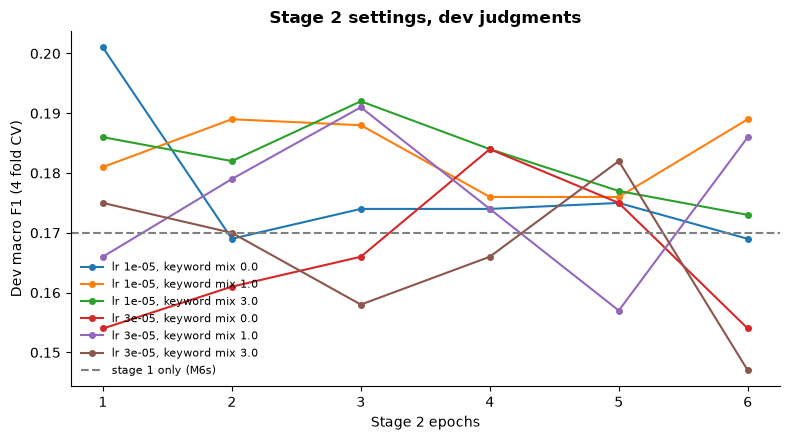

In [8]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 4.5))
for (lr, mix), g in grid[grid.epochs > 0].groupby(["lr", "silver_mix"]):
    ax.plot(g.epochs, g.macro_F1, marker="o", ms=4, label=f"lr {lr:g}, keyword mix {mix}")
ax.axhline(grid.loc[grid.epochs == 0, "macro_F1"].iloc[0], color="gray", ls="--", label="stage 1 only (M6s)")
ax.set_xlabel("Stage 2 epochs")
ax.set_ylabel("Dev macro F1 (4 fold CV)")
ax.set_title(f"Stage 2 settings, dev judgments{TAG}", fontweight="bold")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(fontsize=8, frameon=False)
plt.tight_layout()
plt.savefig(OUT_DIR / f"stage2_grid{GRID_SLUG}.png", dpi=200, facecolor="white")
plt.show()

## M6t: the best stage 2 setting

The setting with the highest dev macro F1 is retrained on all dev judgments and scores the test judgments once. Its dev predictions are the cross validation ones from the search. If no stage 2 setting beats stage 1 alone, M6t is not created: the answer is then that stage 2 does not help with this much lawyer data.

In [9]:
best = grid.sort_values(["macro_F1", "epochs"], ascending=[False, True]).iloc[0]
print("Best on dev:\n", best.to_string())

if best.epochs == 0:
    print("Stage 1 alone beats every stage 2 setting on dev; M6t not created.")
else:
    lr, mix, ep = float(best.lr), int(best.silver_mix), int(best.epochs)
    with np.load(GRID_DIR / f"lr{lr:g}_mix{mix}.npz") as f:
        P = f["P"][ep - 1].astype(int)
    ids, labels = stage2_data(dev_docs, mix, seed=SEED)
    m, _ = train_tracked(load_model(STAGE1_DIR), ids, labels, ep, lr)
    P[TEST_ROWS] = predict(m, GOLD_IDX[TEST_ROWS])
    save_preds("M6t fine-tuned, stage 2 tuned on dev" + TAG, P, predict(m, ALL_IDX))
    free(m)
    print(f"Saved M6t: lr={lr:g}, keyword mix={mix}, epochs={ep}")

Best on dev:
 lr                 0.00001
silver_mix         0.00000
epochs             1.00000
macro_P            0.17200
macro_R            0.29400
macro_F1           0.20100
micro_F1           0.25000
exact_match_acc    0.48900
ci_low             0.12400
ci_high            0.30500
case_macro_F1      0.65300


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 201/201 [00:00<00:00, 4257.94it/s]

Saved M6t: lr=1e-05, keyword mix=0, epochs=1


## Quick check on the dev judgments

Test scores, confidence intervals and comparisons with the other methods are in `06_method_comparison`.

In [10]:
dev_check = pd.DataFrame({name: summarize(Y[~TEST], p["gold"][~TEST]) for name, p in load_preds().items()
                          if name.startswith(("M1 revised", "M6"))}).T.round(3)
dev_check

Skipping M4 hybrid M1 + M2: saved before the gold set changed. Re-run its notebook.


,macro_P,macro_R,macro_F1,micro_F1,exact_match_acc
M1 revised keywords,0.274,0.273,0.270,0.312,0.685
"M6 fine-tuned, keywords then highlights",0.151,0.192,0.169,0.229,0.604
M6g fine-tuned on lawyer highlights,0.089,0.185,0.117,0.181,0.467
M6s fine-tuned on keyword labels,0.201,0.152,0.170,0.247,0.685
"M6t fine-tuned, stage 2 tuned on dev",0.172,0.294,0.201,0.250,0.489
